# Hybrid 1D-CNN + LSTM Intrusion Detection System (UNSW-NB15)

Binary classification (Normal vs. Attack) on the UNSW-NB15 dataset, comparing a **Standalone 1D-CNN**, a **Stacked LSTM**, and the proposed **Hybrid CNN-LSTM**, with edge-readiness metrics (size, parameters, latency) for IoT deployment.

**No-leakage guarantees:** every fitted step — imputation, one-hot vocabulary, MinMax scaler, and ANOVA feature selector — is learned on the **training set only**; SMOTE is applied to the training set only and *after* feature selection; the 20% test set is kept untouched and imbalanced.

> Edit dataset paths in **Cell 2** only. Run the cells top to bottom.

## Cell 1 — Environment setup

Mounts Google Drive so the dataset paths resolve, and makes sure `imbalanced-learn` (used later for SMOTE) is installed on the Colab runtime.

In [ ]:
# Mounts Google Drive so the dataset paths in CELL 2 resolve.
# imbalanced-learn ships with Colab, but we pin-install to be safe.
from google.colab import drive
drive.mount('/content/drive')

# Quiet install — only runs if missing on the runtime.
import importlib
if importlib.util.find_spec('imblearn') is None:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'])

print('Environment ready.')

Mounted at /content/drive
Environment ready.


## Cell 2 — Configuration — *edit paths here only*

Central place for every file path and the shared hyperparameters. Because all three models read these same values (batch size, epochs, patience, split ratio, seed), the comparison between them stays fair. This is the only cell you should need to edit.

In [ ]:
import os

BOT_PATHS = [
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_1.csv',
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_2.csv',
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_3.csv',
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_4.csv',
]
BOT_ROWS_PER_FILE = 100_000

UNSW_PATHS = [
    '/content/drive/MyDrive/FYP_Project/data/UNSW_NB15_training-set/UNSW-NB15_1.csv',
    '/content/drive/MyDrive/FYP_Project/data/UNSW_NB15_training-set/UNSW-NB15_2.csv',
    '/content/drive/MyDrive/FYP_Project/data/UNSW_NB15_training-set/UNSW-NB15_3.csv',
    '/content/drive/MyDrive/FYP_Project/data/UNSW_NB15_training-set/UNSW-NB15_4.csv',
]
UNSW_ROWS_PER_FILE = 100_000

UNSW_COLS = [
    'srcip','sport','dstip','dsport','proto','state','dur','sbytes','dbytes',
    'sttl','dttl','sloss','dloss','service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz','trans_depth','res_bdy_len',
    'Sjit','Djit','Stime','Ltime','Sintpkt','Dintpkt','tcprtt','synack','ackdat',
    'is_sm_ips_ports','ct_state_ttl','ct_flw_http_mthd','is_ftp_login','ct_ftp_cmd',
    'ct_srv_src','ct_srv_dst','ct_dst_ltm','ct_src_ltm','ct_src_dport_ltm',
    'ct_dst_sport_ltm','ct_dst_src_ltm','attack_cat','label'
]

OUTPUT_DIR  = '/content/drive/MyDrive/FYP_Project/models'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Shared hyperparameters — identical for all three models (fair comparison)
BATCH_SIZE  = 128
EPOCHS      = 30
PATIENCE    = 5
TEST_SIZE   = 0.20
VAL_SPLIT   = 0.15
RANDOM_SEED = 42

print('Configuration loaded.')
print(f'All models trained with: batch={BATCH_SIZE}, max_epochs={EPOCHS}, patience={PATIENCE}')

Configuration loaded.
All models trained with: batch=128, max_epochs=30, patience=5


## Cell 3 — Imports & reproducibility

Loads pandas / scikit-learn / imbalanced-learn / TensorFlow, fixes the NumPy and TensorFlow random seeds so runs are repeatable, and sets the feature-selection target to the top 36 features.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, confusion_matrix, roc_curve, auc, classification_report,
)
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D, GlobalAveragePooling1D,
    LSTM, Dense, Dropout,
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Make every run reproducible (split, SMOTE, weight init).
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Feature-selection target (proven optimal in 2024 UNSW-NB15 benchmarks).
TOP_K_FEATURES = 36

print('TensorFlow version:', tf.__version__)
print('GPU available     :', bool(tf.config.list_physical_devices('GPU')))

TensorFlow version: 2.20.0
GPU available     : True


## Cell 4 — Load the raw UNSW-NB15 files

The raw `UNSW-NB15_1..4.csv` capture files have **no header row**, so the column names in `UNSW_COLS` are attached manually. The four files (100k rows each) are concatenated into one corpus of ~400,000 flow records.

In [ ]:
# The raw UNSW-NB15_{1..4}.csv files have NO header row, so we
# attach UNSW_COLS explicitly. We use ONLY the UNSW dataset here
# (Bot-IoT paths are intentionally ignored per the study scope).
def load_unsw(paths, names, rows_per_file):
    frames = []
    for p in paths:
        if not os.path.exists(p):
            print(f'  [WARN] missing file skipped: {p}')
            continue
        # low_memory=False avoids mixed-dtype chunk warnings on raw data.
        df = pd.read_csv(p, header=None, names=names,
                         nrows=rows_per_file, low_memory=False)
        frames.append(df)
        print(f'  loaded {len(df):>7,} rows from {os.path.basename(p)}')
    if not frames:
        raise FileNotFoundError('No UNSW-NB15 files found — check CELL 2 paths.')
    return pd.concat(frames, ignore_index=True)

print('Loading UNSW-NB15 ...')
df = load_unsw(UNSW_PATHS, UNSW_COLS, UNSW_ROWS_PER_FILE)
print(f'Combined dataset shape: {df.shape}')
print('Class balance (0=Normal, 1=Attack):')
print(df['label'].value_counts(normalize=True).rename('proportion'))

Loading UNSW-NB15 ...
  loaded 100,000 rows from UNSW-NB15_1.csv
  loaded 100,000 rows from UNSW-NB15_2.csv
  loaded 100,000 rows from UNSW-NB15_3.csv
  loaded 100,000 rows from UNSW-NB15_4.csv
Combined dataset shape: (400000, 49)
Class balance (0=Normal, 1=Attack):
label
0    0.853352
1    0.146647
Name: proportion, dtype: float64


## Cell 5 — Drop leaky identifier columns

Removes source/destination IPs and ports, the absolute timestamps, and the granular `attack_cat` label. These would let the model memorise specific hosts, sessions, or capture times instead of learning real traffic behaviour. This leaves **41 features**.

In [ ]:
# Leaky identifiers must go BEFORE any learning so the model
# generalises to flows, not to specific hosts/sessions:
#   srcip, dstip          -> raw IP addresses (host identity leak)
#   sport, dsport         -> source/dest ports (often hex; weak ID leak)
#   Stime, Ltime          -> absolute timestamps (temporal leak)
#   attack_cat            -> attack SUBCATEGORY (label leak for binary task)
LEAKY_COLS = ['srcip', 'dstip', 'sport', 'dsport', 'Stime', 'Ltime', 'attack_cat']
df = df.drop(columns=[c for c in LEAKY_COLS if c in df.columns])

# Target + features.
TARGET = 'label'
y_all = pd.to_numeric(df[TARGET], errors='coerce').fillna(0).astype(int)
X_all = df.drop(columns=[TARGET])

print(f'After dropping leaks -> features: {X_all.shape[1]}, samples: {X_all.shape[0]}')
print('Dropped:', LEAKY_COLS)

After dropping leaks -> features: 41, samples: 400000
Dropped: ['srcip', 'dstip', 'sport', 'dsport', 'Stime', 'Ltime', 'attack_cat']


## Cell 6 — Clean, impute, one-hot encode, and split

Numeric columns are coerced to numbers and missing values filled with the training **median**; categoricals filled with the training **mode**. The nominal fields (`proto`, `state`, `service`) are **one-hot encoded** (avoiding false ordinality), expanding the matrix to ~202 columns. A **stratified 80/20 split** then preserves the Normal/Attack ratio in both partitions. Every statistic is learned on the training set only.

In [ ]:
# Nominal categoricals get One-Hot Encoding (NO label encoding —
# label encoding would inject false ordinality into proto/state/service).
CATEGORICAL_COLS = [c for c in ['proto', 'state', 'service'] if c in X_all.columns]
NUMERIC_COLS     = [c for c in X_all.columns if c not in CATEGORICAL_COLS]

# Raw UNSW columns sometimes carry stray strings/spaces in numeric fields
# (e.g. ct_ftp_cmd). Coerce to numeric so imputation/scaling are valid.
for c in NUMERIC_COLS:
    X_all[c] = pd.to_numeric(X_all[c], errors='coerce')

# Normalise categorical text (strip spaces, unify the UNSW '-' = "none").
for c in CATEGORICAL_COLS:
    X_all[c] = X_all[c].astype(str).str.strip().replace({'': '-', 'nan': '-'})

# --- Stratified 80/20 split BEFORE fitting anything (no leakage) -----------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=TEST_SIZE,
    stratify=y_all,            # preserve Normal/Attack ratio in both splits
    random_state=RANDOM_SEED,
)
print(f'Train: {X_train_raw.shape[0]:,}  |  Test: {X_test_raw.shape[0]:,}')

# --- Imputation: learn statistics on TRAIN ONLY, apply to both -------------
num_medians = X_train_raw[NUMERIC_COLS].median()
cat_modes   = X_train_raw[CATEGORICAL_COLS].mode().iloc[0]

X_train_raw[NUMERIC_COLS] = X_train_raw[NUMERIC_COLS].fillna(num_medians)
X_test_raw[NUMERIC_COLS]  = X_test_raw[NUMERIC_COLS].fillna(num_medians)
X_train_raw[CATEGORICAL_COLS] = X_train_raw[CATEGORICAL_COLS].fillna(cat_modes)
X_test_raw[CATEGORICAL_COLS]  = X_test_raw[CATEGORICAL_COLS].fillna(cat_modes)

# --- One-Hot Encoding -------------------------------------------------------
# Encode train, then REINDEX test to the train vocabulary so both sets share
# identical columns (categories unseen in train -> all-zero, as they should).
X_train_enc = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLS)
X_test_enc  = pd.get_dummies(X_test_raw,  columns=CATEGORICAL_COLS)
X_test_enc  = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

# Cast to float32 (bool dummies -> numeric; lighter for the edge model).
X_train_enc = X_train_enc.astype('float32')
X_test_enc  = X_test_enc.astype('float32')

feature_names = X_train_enc.columns.to_numpy()
print(f'Features after One-Hot Encoding: {X_train_enc.shape[1]}')

Train: 320,000  |  Test: 80,000
Features after One-Hot Encoding: 202


## Cell 7 — MinMax scaling (fit on train only)

Scales every feature to the [0, 1] range. The scaler is **fit on the training set only** and merely applied to the test set, so no test-set information leaks into the model.

In [ ]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)   # learns min/max on TRAIN
X_test_scaled  = scaler.transform(X_test_enc)        # TEST merely transformed
print('Scaling complete. Range now [0, 1] for all features.')

Scaling complete. Range now [0, 1] for all features.


## Cell 8 — ANOVA F-test feature selection (top 36)

`SelectKBest` with the ANOVA F-test scores each feature by how strongly it separates Normal from Attack, and keeps the **36 highest-scoring** features. It is fit on the real, pre-SMOTE training data, then the same 36 columns are applied to the test set.

In [ ]:
# IMPORTANT ordering decision (defense point):
#   SelectKBest is fit on the REAL, pre-SMOTE training set. Fitting it on
#   synthetic SMOTE samples would bias F-scores toward interpolated data.
#   We then carry the SAME 36 selected columns to the test set.
k = min(TOP_K_FEATURES, X_train_scaled.shape[1])
selector = SelectKBest(score_func=f_classif, k=k)
X_train_sel = selector.fit_transform(X_train_scaled, y_train)   # fit on TRAIN
X_test_sel  = selector.transform(X_test_scaled)                 # apply to TEST

selected_mask    = selector.get_support()
selected_feature_names = feature_names[selected_mask]
print(f'Selected {k} / {X_train_scaled.shape[1]} features via ANOVA F-test.')
print('Top features:', list(selected_feature_names))

Selected 36 / 202 features via ANOVA F-test.
Top features: ['dbytes', 'sttl', 'dttl', 'dloss', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'tcprtt', 'synack', 'ackdat', 'ct_state_ttl', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'proto_tcp', 'proto_udp', 'proto_unas', 'state_CON', 'state_FIN', 'state_INT', 'service_-', 'service_dns', 'service_ftp-data', 'service_pop3', 'service_ssh']


In [ ]:
# ==========================================================================
# Cell 8b — Export preprocess.json  (fitted transform for app.py + Tier-2)
# --------------------------------------------------------------------------
# Captures every fitted preprocessing statistic so raw UNSW flows can be
# transformed *identically* outside this notebook — the dashboard's exact
# path and the Tier-2 fidelity gate both depend on this file.
# Must run AFTER Cell 8 (scaler + selector fitted), BEFORE SMOTE.
# ==========================================================================
import json

preprocess = {
    'dataset'               : 'UNSW-NB15',
    'leaky_cols'            : list(LEAKY_COLS),
    'categorical_cols'      : list(CATEGORICAL_COLS),
    'numeric_medians'       : {str(k): float(v) for k, v in num_medians.items()},
    'cat_modes'             : {str(k): str(v)   for k, v in cat_modes.items()},
    'ohe_vocab'             : [str(c) for c in feature_names],
    'scaler_min'            : [float(x) for x in scaler.data_min_],
    'scaler_max'            : [float(x) for x in scaler.data_max_],
    'selected_feature_names': [str(c) for c in selected_feature_names],
}

# Fail loudly if anything is misaligned (better here than silently in the app).
assert len(preprocess['ohe_vocab']) == len(preprocess['scaler_min']) == \
       len(preprocess['scaler_max']), 'scaler length must match ohe_vocab'
assert all(f in preprocess['ohe_vocab']
           for f in preprocess['selected_feature_names']), \
       'every selected feature must be in ohe_vocab'
assert len(preprocess['selected_feature_names']) == X_train_sel.shape[1], \
       'selected count must equal model input width'

out_path = f'{OUTPUT_DIR}/preprocess.json'
with open(out_path, 'w') as f:
    json.dump(preprocess, f, indent=2)

print(f'[✓] Wrote {out_path}')
print(f'    ohe_vocab: {len(preprocess["ohe_vocab"])} cols  |  '
      f'selected: {len(preprocess["selected_feature_names"])} features')

[✓] Wrote /content/drive/MyDrive/FYP_Project/models/preprocess.json
    ohe_vocab: 202 cols  |  selected: 36 features


## Cell 9 — SMOTE on the training set only

The Synthetic Minority Over-sampling Technique balances the Normal and Attack classes by interpolating new minority samples — applied to the **training set only**. The test set is left imbalanced so evaluation reflects real-world conditions.

In [ ]:
# Balance Normal vs Attack ONLY in training. The test set stays
# imbalanced (real-world distribution) for honest evaluation.
print('Before SMOTE:', dict(pd.Series(y_train).value_counts()))
smote = SMOTE(random_state=RANDOM_SEED)
X_train_bal, y_train_bal = smote.fit_resample(X_train_sel, y_train)
print('After  SMOTE:', dict(pd.Series(y_train_bal).value_counts()))

Before SMOTE: {0: np.int64(273073), 1: np.int64(46927)}
After  SMOTE: {0: np.int64(273073), 1: np.int64(273073)}


## Cell 10 — Reshape to 3D for Conv1D / LSTM

Converts the 2D table `(samples, 36)` into the 3D tensor `(samples, 36, 1)` that the convolutional and recurrent layers expect — treating the 36 features as a length-36 sequence.

In [ ]:
# (samples, 36) -> (samples, 36, 1): treat the 36 features as a
# length-36 sequence with a single channel.
N_FEATURES = X_train_bal.shape[1]
X_train_3d = X_train_bal.reshape(-1, N_FEATURES, 1).astype('float32')
X_test_3d  = X_test_sel.reshape(-1,  N_FEATURES, 1).astype('float32')
y_train_bal = np.asarray(y_train_bal).astype('float32')
y_test_arr  = np.asarray(y_test).astype('float32')

INPUT_SHAPE = (N_FEATURES, 1)
print(f'Train tensor: {X_train_3d.shape}  |  Test tensor: {X_test_3d.shape}')

Train tensor: (546146, 36, 1)  |  Test tensor: (80000, 36, 1)


## Cell 11 — Model builders — three architectures

Defines the three networks compared in this study: a **Standalone 1D CNN**, a **Stacked LSTM**, and the proposed **Hybrid CNN-LSTM**. All use binary cross-entropy loss and the Adam optimiser.

In [ ]:
def build_cnn(input_shape):
    """Baseline 1: Standalone 1D CNN."""
    model = Sequential(name='Standalone_1D_CNN')
    model.add(Input(shape=input_shape))
    model.add(Conv1D(64,  kernel_size=3, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Conv1D(128, kernel_size=3, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(GlobalAveragePooling1D())
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_lstm(input_shape):
    """Baseline 2: Stacked LSTM (2024-benchmark style)."""
    model = Sequential(name='Stacked_LSTM')
    model.add(Input(shape=input_shape))
    model.add(LSTM(128, return_sequences=True))
    model.add(Dropout(0.3))
    model.add(LSTM(32,  return_sequences=False))
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_hybrid(input_shape):
    """Target Model: Hybrid 1D CNN + LSTM."""
    model = Sequential(name='Hybrid_CNN_LSTM')
    model.add(Input(shape=input_shape))
    model.add(Conv1D(64, kernel_size=3, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.2))
    model.add(LSTM(64, return_sequences=False))
    model.add(Dropout(0.3))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model

## Cell 12 — Callbacks & unified training routine

Sets up `EarlyStopping` (restores the best weights) and `ReduceLROnPlateau` (lowers the learning rate on a plateau), then trains all three models with the identical routine so the comparison is fair.

In [ ]:
def make_callbacks():
    """Fresh callbacks per model (state must not be shared)."""
    return [
        EarlyStopping(monitor='val_loss', patience=PATIENCE,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=3, min_lr=1e-6, verbose=1),
    ]


def train_model(build_fn, name):
    """Build -> train -> return (model, history). Identical setup for all 3."""
    print('\n' + '=' * 60)
    print(f'TRAINING: {name}')
    print('=' * 60)
    model = build_fn(INPUT_SHAPE)
    model.summary()
    history = model.fit(
        X_train_3d, y_train_bal,
        validation_split=VAL_SPLIT,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=make_callbacks(),
        verbose=1,
    )
    return model, history


# Train all three with the SAME data, batch size, epochs and callbacks.
cnn_model,    cnn_hist    = train_model(build_cnn,    'Standalone 1D CNN')
lstm_model,   lstm_hist   = train_model(build_lstm,   'Stacked LSTM')
hybrid_model, hybrid_hist = train_model(build_hybrid, 'Hybrid CNN-LSTM')


TRAINING: Standalone 1D CNN


Model: "Standalone_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 36, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 36, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 18, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 18, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 18, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,049 (133.00 KB)

 Trainable params: 33,665 (131.50 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 36, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 36, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 18, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,649 (139.25 KB)

 Trainable params: 35,521 (138.75 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - accuracy: 0.9866 - loss: 0.0402 - val_accuracy: 0.9985 - val_loss: 0.0242 - learning_rate: 0.0010
Epoch 2/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 32s 9ms/step - accuracy: 0.9906 - loss: 0.0271 - val_accuracy: 0.9996 - val_loss: 0.0196 - learning_rate: 0.0010
Epoch 3/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 41s 9ms/step - accuracy: 0.9910 - loss: 0.0251 - val_accuracy: 0.9998 - val_loss: 0.0171 - learning_rate: 0.0010
Epoch 4/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 32s 9ms/step - accuracy: 0.9910 - loss: 0.0243 - val_accuracy: 1.0000 - val_loss: 0.0215 - learning_rate: 0.0010
Epoch 5/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 34s 9ms/step - accuracy: 0.9910 - loss: 0.0238 - val_accuracy: 1.0000 - val_loss: 0.0167 - learning_rate: 0.0010
Epoch 6/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 32s 9ms/step - accuracy: 0.9910 - loss: 0.0233 - val_accuracy: 1.0000 - val_loss: 0.0176 - learning_rate: 0.0010
Epoch 7/30
3627/3627 ━━━━━━━━━━━━━━━━━━━━ 32s 9ms/step - accuracy: 0.9

## Cell 13 — Edge-readiness metric helpers

Helper functions that compute the model size in KB (parameters × 4 bytes) and the average single-flow inference latency in milliseconds — the evidence for IoT edge feasibility.

In [ ]:
def measure_latency_ms(model, sample, n_runs=200, warmup=20):
    """Average single-flow inference latency in milliseconds (compiled call, bypasses Keras predict() overhead)."""
    x = tf.constant(sample.reshape(1, *sample.shape))
    infer = tf.function(lambda inp: model(inp, training=False))
    for _ in range(warmup):
        infer(x)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        infer(x)
    return (time.perf_counter() - t0) / n_runs * 1000.0

def model_size_kb(model):
    """Model size in kilobytes (sum of params, each param is 4 bytes)."""
    total_params = model.count_params()
    return total_params * 4 / 1024.0

## Cell 14 — Evaluate & collect all metrics

Runs each trained model on the unseen test set and collects accuracy, precision, recall, F1, MCC, AUC, the confusion matrix, and the edge metrics into one results structure.

In [ ]:
def evaluate_model(model, name):
    """Compute standard + edge metrics on the imbalanced TEST set."""
    y_prob = model.predict(X_test_3d, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    fpr, tpr, _ = roc_curve(y_test_arr, y_prob)
    roc_auc = auc(fpr, tpr)

    metrics = {
        'name'      : name,
        'accuracy'  : accuracy_score(y_test_arr, y_pred),
        'precision' : precision_score(y_test_arr, y_pred, zero_division=0),
        'recall'    : recall_score(y_test_arr, y_pred, zero_division=0),
        'f1'        : f1_score(y_test_arr, y_pred, zero_division=0),
        'mcc'       : matthews_corrcoef(y_test_arr, y_pred),
        'auc'       : roc_auc,
        'cm'        : confusion_matrix(y_test_arr, y_pred),
        'fpr'       : fpr,
        'tpr'       : tpr,
        'params'    : model.count_params(),
        'size_kb'   : model_size_kb(model),
        'latency_ms': measure_latency_ms(model, X_test_3d[0]),
    }
    print(f'\n--- {name} ---')
    print(classification_report(y_test_arr, y_pred,
                                target_names=['Normal', 'Attack'], digits=4))
    return metrics


results = [
    evaluate_model(cnn_model,    'Standalone 1D CNN'),
    evaluate_model(lstm_model,   'Stacked LSTM'),
    evaluate_model(hybrid_model, 'Hybrid CNN-LSTM'),
]


--- Standalone 1D CNN ---
              precision    recall  f1-score   support

      Normal     1.0000    0.9846    0.9922     68268
      Attack     0.9177    0.9999    0.9570     11732

    accuracy                         0.9868     80000
   macro avg     0.9588    0.9923    0.9746     80000
weighted avg     0.9879    0.9868    0.9871     80000


--- Stacked LSTM ---
              precision    recall  f1-score   support

      Normal     0.9997    0.9831    0.9913     68268
      Attack     0.9101    0.9985    0.9522     11732

    accuracy                         0.9853     80000
   macro avg     0.9549    0.9908    0.9718     80000
weighted avg     0.9866    0.9853    0.9856     80000


--- Hybrid CNN-LSTM ---
              precision    recall  f1-score   support

      Normal     0.9996    0.9863    0.9929     68268
      Attack     0.9258    0.9974    0.9603     11732

    accuracy                         0.9879     80000
   macro avg     0.9627    0.9919    0.9766     80000


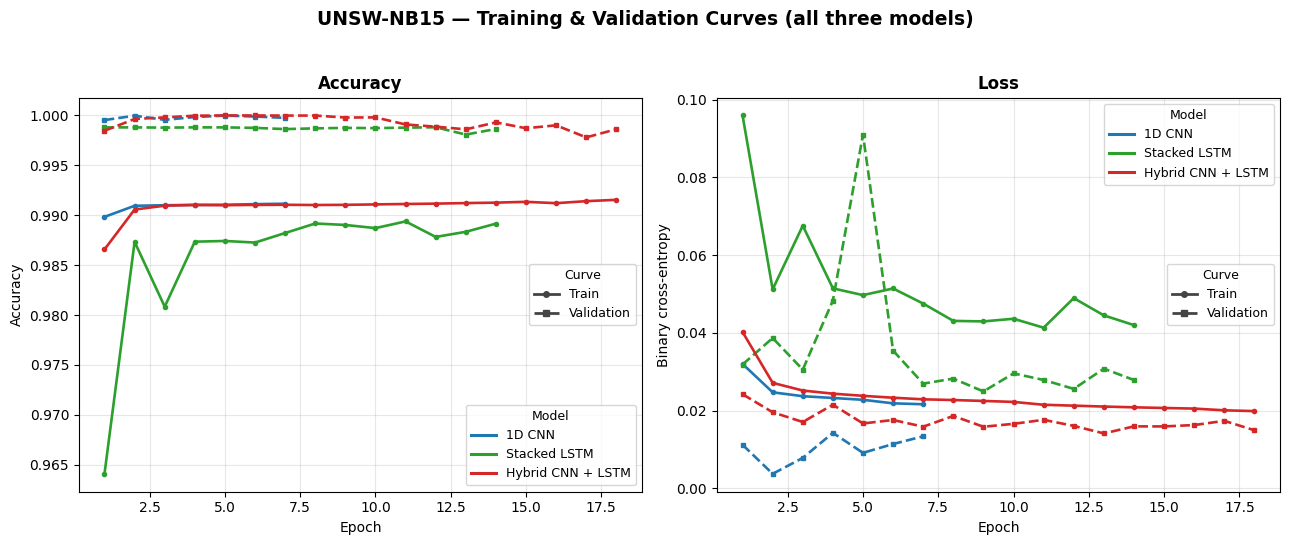

In [ ]:
# ============================================================
# Training & validation curves — all three models overlaid
# Run AFTER the training cell (needs cnn_hist / lstm_hist / hybrid_hist)
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- set this per notebook: 'UNSW-NB15' or 'BoT-IoT' ---
DATASET_NAME = 'UNSW-NB15'

MODELS = {                              # label -> (History, colour)
    '1D CNN':            (cnn_hist,    '#1f77b4'),
    'Stacked LSTM':      (lstm_hist,   '#2ca02c'),
    'Hybrid CNN + LSTM': (hybrid_hist, '#d62728'),
}

def _h(hist):   return hist.history if hasattr(hist, 'history') else hist
def _key(hd, *names):
    for n in names:
        if n in hd: return hd[n]
    raise KeyError(f"none of {names} in {list(hd.keys())}")

fig, (axA, axL) = plt.subplots(1, 2, figsize=(13, 5.4))
for label, (hist, c) in MODELS.items():
    hd = _h(hist)
    acc  = _key(hd, 'accuracy', 'acc');   vacc  = _key(hd, 'val_accuracy', 'val_acc')
    loss = _key(hd, 'loss');              vloss = _key(hd, 'val_loss')
    x = range(1, len(acc) + 1)
    axA.plot(x, acc,  '-',  color=c, lw=1.9, marker='o', ms=3)
    axA.plot(x, vacc, '--', color=c, lw=1.9, marker='s', ms=3)
    axL.plot(x, loss, '-',  color=c, lw=1.9, marker='o', ms=3)
    axL.plot(x, vloss,'--', color=c, lw=1.9, marker='s', ms=3)

axA.set_title('Accuracy', fontsize=12, fontweight='bold')
axA.set_xlabel('Epoch'); axA.set_ylabel('Accuracy'); axA.grid(True, alpha=0.3)
axL.set_title('Loss', fontsize=12, fontweight='bold')
axL.set_xlabel('Epoch'); axL.set_ylabel('Binary cross-entropy'); axL.grid(True, alpha=0.3)

model_h = [Line2D([0],[0], color=c, lw=2.2, label=lbl) for lbl,(_,c) in MODELS.items()]
style_h = [Line2D([0],[0], color='#444', lw=2, ls='-',  marker='o', ms=4, label='Train'),
           Line2D([0],[0], color='#444', lw=2, ls='--', marker='s', ms=4, label='Validation')]
for ax, mloc, sloc in [(axA,'lower right','center right'), (axL,'upper right','center right')]:
    leg = ax.legend(handles=model_h, title='Model', fontsize=9, title_fontsize=9, loc=mloc)
    ax.add_artist(leg)
    ax.legend(handles=style_h, title='Curve', fontsize=9, title_fontsize=9, loc=sloc)

fig.suptitle(f'{DATASET_NAME} — Training & Validation Curves (all three models)',
             fontsize=13.5, fontweight='bold', y=1.00)
fig.tight_layout(rect=[0, 0, 1, 0.97])

# optional: save a high-res copy to Drive
# fig.savefig('/content/drive/MyDrive/FYP_Project/fig_4_3_training_curves.png',
#             dpi=200, bbox_inches='tight')
plt.show()

## Cell 15 — Unified comparison report

Assembles every model's metrics into a single table, prints it, and saves it to CSV for the dissertation appendix.

In [ ]:
report = pd.DataFrame([{
    'Model'            : r['name'],
    'Accuracy'         : r['accuracy'],
    'Precision'        : r['precision'],
    'Recall'           : r['recall'],
    'F1-Score'         : r['f1'],
    'MCC'              : r['mcc'],
    'AUC'              : r['auc'],
    'Params'           : r['params'],
    'Size (KB)'        : r['size_kb'],
    'Latency (ms)'     : r['latency_ms'],
} for r in results])

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
print('\n' + '=' * 70)
print('UNIFIED MODEL COMPARISON  (test set = 20% unseen, imbalanced)')
print('=' * 70)
print(report.to_string(index=False))

# Persist the report for the dissertation appendix.
report.to_csv(os.path.join(OUTPUT_DIR, 'ids_comparison_report.csv'), index=False)
print(f'\nReport saved to {OUTPUT_DIR}/ids_comparison_report.csv')


UNIFIED MODEL COMPARISON  (test set = 20% unseen, imbalanced)
            Model  Accuracy  Precision  Recall  F1-Score    MCC    AUC  Params  Size (KB)  Latency (ms)
Standalone 1D CNN    0.9868     0.9177  0.9999    0.9570 0.9505 0.9995   34049   133.0039        0.9643
     Stacked LSTM    0.9853     0.9101  0.9985    0.9522 0.9450 0.9977   89345   349.0039        2.0368
  Hybrid CNN-LSTM    0.9879     0.9258  0.9974    0.9603 0.9541 0.9996   35649   139.2539        1.3588

Report saved to /content/drive/MyDrive/FYP_Project/models/ids_comparison_report.csv


## Cell 16 — Confusion matrices

Plots the confusion matrix of all three models side by side.

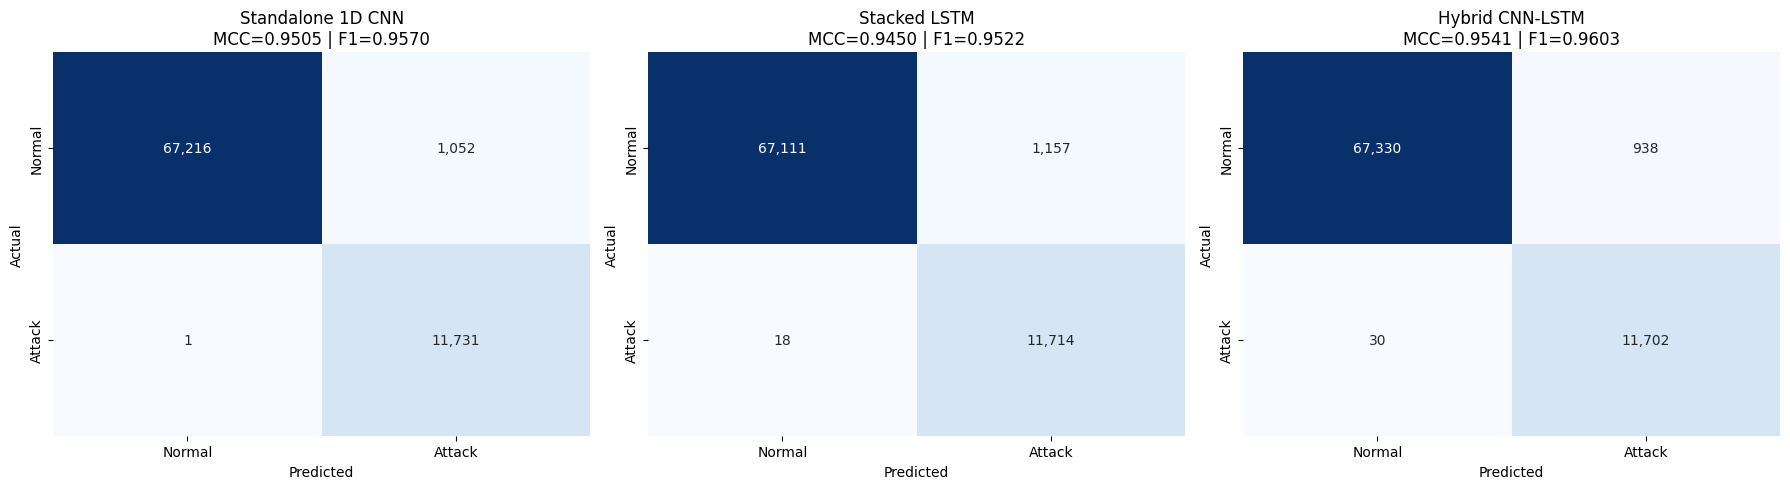

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, r in zip(axes, results):
    sns.heatmap(r['cm'], annot=True, fmt=',d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'Attack'],
                yticklabels=['Normal', 'Attack'], ax=ax)
    ax.set_title(f"{r['name']}\nMCC={r['mcc']:.4f} | F1={r['f1']:.4f}")
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrices.png'), dpi=150)
plt.show()

## Cell 17 — AUC-ROC curves

Overlays the ROC curves of the three models on one axis for a direct visual comparison.

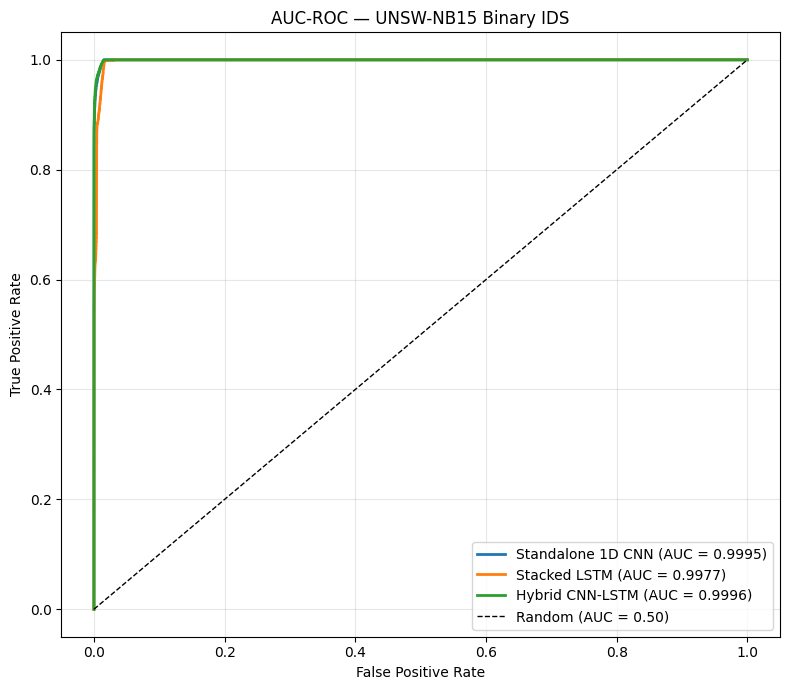

In [ ]:
plt.figure(figsize=(8, 7))
for r in results:
    plt.plot(r['fpr'], r['tpr'], lw=2,
             label=f"{r['name']} (AUC = {r['auc']:.4f})")
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.50)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('AUC-ROC — UNSW-NB15 Binary IDS')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'roc_curves.png'), dpi=150)
plt.show()

## Cell 18 — Edge-readiness summary & save models

Prints the parameter count, size, and latency of each model, then saves the three trained models as `.keras` files for deployment or the appendix.

In [ ]:
print('\n' + '=' * 70)
print('IoT EDGE-READINESS SUMMARY')
print('=' * 70)
for r in results:
    print(f"{r['name']:<22} | params: {r['params']:>8,} | "
          f"size: {r['size_kb']:>8.2f} KB | "
          f"latency: {r['latency_ms']:>6.3f} ms/flow")

# Save trained models (.keras) for deployment / appendix.
for model, fname in [(cnn_model,    'cnn_ids.keras'),
                     (lstm_model,   'lstm_ids.keras'),
                     (hybrid_model, 'hybrid_ids.keras')]:
    path = os.path.join(OUTPUT_DIR, fname)
    model.save(path)
    print(f'  saved {fname}  ({os.path.getsize(path) / 1024:.1f} KB on disk)')

print('\nPipeline complete.')


IoT EDGE-READINESS SUMMARY
Standalone 1D CNN      | params:   34,049 | size:   133.00 KB | latency:  0.964 ms/flow
Stacked LSTM           | params:   89,345 | size:   349.00 KB | latency:  2.037 ms/flow
Hybrid CNN-LSTM        | params:   35,649 | size:   139.25 KB | latency:  1.359 ms/flow
  saved cnn_ids.keras  (444.3 KB on disk)
  saved lstm_ids.keras  (1088.0 KB on disk)
  saved hybrid_ids.keras  (462.5 KB on disk)

Pipeline complete.


*italicised text*## Cell 20 — Optional: model-agnostic dashboard data loading

### Dynamic Data Loading for Model-Agnostic Dashboard

First, you'll need to save your preprocessed `X_test_sel` and `y_test` for both datasets (UNSW and Bot-IoT) into separate CSV files. The example you provided is for UNSW. You'd do the same for Bot-IoT if you trained a model on that dataset:

```python
# This code would be run after training your Bot-IoT model and preparing its X_test_sel and y_test
# Make sure to replace `selected_feature_names_bot_iot` and `y_test_bot_iot` with your actual Bot-IoT variables
# exact_bot_iot = pd.DataFrame(np.asarray(X_test_sel_bot_iot), columns=list(selected_feature_names_bot_iot))
# exact_bot_iot['label'] = np.asarray(y_test_bot_iot).astype(int)
# exact_bot_iot.to_csv(f'{OUTPUT_DIR}/bot_iot_test_preprocessed.csv', index=False)
```

Once you have these preprocessed files, your dashboard application can dynamically load the correct data based on the loaded model's expected input shape. Here's a conceptual code block for your dashboard:

### Cell 21 — Dashboard data loader (demonstration)

Loads a saved `.keras` model, reads the expected input feature count from its input shape, and dynamically loads the matching preprocessed test set. This is a deployment helper, not part of training — run it only if you have exported the preprocessed test CSVs.

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import os

# Assume OUTPUT_DIR is defined from your notebook configuration
OUTPUT_DIR = '/content/drive/MyDrive/FYP_Project/models'

# --- Step 1: Define paths for your preprocessed data ---
UNSW_PREPROCESSED_PATH = os.path.join(OUTPUT_DIR, 'unsw_test_preprocessed.csv')
BOT_IOT_PREPROCESSED_PATH = os.path.join(OUTPUT_DIR, 'bot_iot_test_preprocessed.csv') # Assuming you've created this

# --- Step 2: Helper function to load preprocessed data ---
def load_preprocessed_data(file_path):
    if not os.path.exists(file_path):
        print(f"Error: Preprocessed file not found at {file_path}")
        return None, None
    df = pd.read_csv(file_path)
    X = df.drop(columns=['label']).values.astype('float32')
    y = df['label'].values.astype('float32')
    return X, y

# --- Step 3: Example of loading a model and dynamically selecting data ---

# Load your hybrid model (replace with actual model loading logic in your dashboard)
# For demonstration, let's assume `hybrid_model` from the notebook is available.
# In a real deployment, you'd load it from a .keras or .tflite file.

# Example: Simulating loading a model
# If you're loading a .keras model:
model_path = os.path.join(OUTPUT_DIR, 'hybrid_ids.keras')
print(f"Attempting to load model from: {model_path}")
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model file not found at {model_path}. Please ensure it was saved correctly and Google Drive is mounted.")
loaded_model = tf.keras.models.load_model(model_path)
# If you're loading a .tflite model:
# interpreter = tf.lite.Interpreter(model_path=os.path.join(OUTPUT_DIR, 'hybrid_ids_edge.tflite'))
# interpreter.allocate_tensors()
# input_details = interpreter.get_input_details()
# input_shape_model = input_details[0]['shape']

# For this demonstration, we'll use the 'hybrid_model' object directly from the notebook's scope
# In your dashboard, you would load the model from disk first.
# loaded_model = hybrid_model # Assuming hybrid_model is still in scope from previous cells

# Get the expected input shape from the model
# For Keras models, input_shape is typically model.input_shape or model.layers[0].input_shape
input_shape_model = loaded_model.input_shape

# The number of features the model expects is the second element of the input shape tuple
# (batch_size, num_features, 1) -> num_features is input_shape_model[1]
expected_num_features = input_shape_model[1]
print(f"Loaded model expects {expected_num_features} features.")

# Dynamically load the correct preprocessed data
if expected_num_features == 36:
    print("Model expects UNSW-NB15 features. Loading UNSW preprocessed data...")
    X_dashboard, y_dashboard = load_preprocessed_data(UNSW_PREPROCESSED_PATH)
elif expected_num_features == 20: # Assuming Bot-IoT uses 20 features
    print("Model expects Bot-IoT features. Loading Bot-IoT preprocessed data...")
    X_dashboard, y_dashboard = load_preprocessed_data(BOT_IOT_PREPROCESSED_PATH)
else:
    print(f"Warning: Unknown feature count {expected_num_features}. Cannot load appropriate data.")
    X_dashboard, y_dashboard = None, None

if X_dashboard is not None:
    print(f"Dashboard data loaded with shape: {X_dashboard.shape}")
    # Reshape for the model if needed (e.g., for CNN/LSTM models requiring 3D input)
    X_dashboard_3d = X_dashboard.reshape(-1, expected_num_features, 1)

    # Now you can use X_dashboard_3d and y_dashboard for predictions or evaluation in your dashboard
    # Example: Make a prediction
    sample_prediction = loaded_model.predict(X_dashboard_3d[:1])
    print(f"Prediction for first sample: {sample_prediction[0][0]:.4f}")

# If you wanted to allow raw CSV uploads, you would also need to re-implement the
# preprocessing steps (imputation, OHE, scaling, feature selection) using the
# *fitted* `scaler` and `selector` objects saved from your training phase. This ensures
# consistency. Loading preprocessed data is much simpler for deployment.

Attempting to load model from: /content/drive/MyDrive/FYP_Project/models/hybrid_ids.keras
Loaded model expects 36 features.
Model expects UNSW-NB15 features. Loading UNSW preprocessed data...
Error: Preprocessed file not found at /content/drive/MyDrive/FYP_Project/models/unsw_test_preprocessed.csv


In [ ]:
import pandas as pd, numpy as np
exact = pd.DataFrame(np.asarray(X_test_sel), columns=list(selected_feature_names))
exact['label'] = np.asarray(y_test).astype(int)
exact.to_csv(f'{OUTPUT_DIR}/UNSW_test_preprocessed.csv', index=False)

In [ ]:
import os
print("Models in memory:", all(n in dir() for n in ['cnn_model','lstm_model','hybrid_model']))
print("Test data in memory:", 'X_test_3d' in dir())
print("Saved .keras files exist:",
      os.path.exists('/content/drive/MyDrive/FYP_Project/models/hybrid_ids.keras'))

Models in memory: False
Test data in memory: True
Saved .keras files exist: True
